<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank y HITS en la red de citas cit-HepPh</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Representación dispersa del grafo, matriz de transición, PageRank con teletransportación y hubs y autoridades de HITS.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Medir la **importancia de cada artículo** de la red de citas cit-HepPh a partir de la estructura de enlaces, no solo
del número de citas que recibe. Primero se representa el grafo como una **matriz dispersa** y se construye la matriz
de transición $M$ del paseo aleatorio, revisando los dos obstáculos clásicos: los nodos colgantes y las trampas de
araña. Sobre esa base se calculan **PageRank** y **HITS** (hubs y autoridades) y se comparan.

### Los datos

Se usan las salidas de `01_eda_calidad_preprocesamiento.ipynb` en `data/processed/`:

- `aristas_limpias.parquet`: 421,534 citas *i → j* sin autocitas, con las marcas `es_reciproca` y `es_futuro`.
- `nodos_limpios.parquet`: 34,546 artículos con `fecha`, `mes_id`, `anio_id` y sus grados.

Este notebook no hace limpieza.

### Contenido

1. **Datos limpios.** Carga y resumen de las dos tablas.
2. **Matriz de adyacencia dispersa.** Reindexación a `0..n-1`, matriz CSR, memoria frente a la versión densa y patrón
   de la matriz en orden cronológico.
3. **Matriz de transición.** $M$ estocástica por columnas, nodos colgantes, trampas de araña y guardado de la matriz.
   En 3.1 se define el **grafo de análisis**, sin las citas al futuro.
4. **PageRank** con `networkx` sobre el grafo de análisis:
   - 4.1 sensibilidad a $eta$;
   - 4.2 relación con el número de citas;
   - 4.3 sesgo por antigüedad y ajuste por cohorte;
   - 4.4 robustez: con y sin citas al futuro, y los casos `9908362` y `0111190`.
5. **HITS** (hubs y autoridades) con `networkx`:
   - 5.1 comprobación de la relación con la SVD;
   - 5.2 quiénes son los hubs y las autoridades;
   - 5.3 comparación con PageRank y efecto TKC.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
ARCHIVO_MATRIZ = RUTA_PROCESADOS / "adyacencia.npz"

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
# Escala secuencial de un solo tono (azules) para conteos y densidades; vacío = blanco
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    """Formatea un número de bytes en MB o GB decimales (10⁶ y 10⁹ bytes)."""
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos limpios</span></div>


Se cargan las dos tablas del notebook 1 y se comprueba que siguen cumpliendo las condiciones que se verificaron antes
de guardarlas.

In [2]:
# Carga de las aristas y los nodos limpios y resumen de dimensiones
aristas = pd.read_parquet(RUTA_PROCESADOS / "aristas_limpias.parquet")
nodos = pd.read_parquet(RUTA_PROCESADOS / "nodos_limpios.parquet")

resumen = pd.Series({
    "Aristas (citas i → j)": f"{len(aristas):,}",
    "Nodos (artículos)": f"{len(nodos):,}",
    "Aristas recíprocas (es_reciproca)": f"{aristas['es_reciproca'].sum():,} ({pct(aristas['es_reciproca'].mean(), 3)})",
    "Citas al futuro (es_futuro)": f"{aristas['es_futuro'].sum():,} ({pct(aristas['es_futuro'].mean(), 3)})",
    "Nodos con fecha exacta": f"{nodos['fecha'].notna().sum():,} ({pct(nodos['fecha'].notna().mean())})",
    "Nodos colgantes (k_out = 0)": f"{nodos['es_colgante'].sum():,} ({pct(nodos['es_colgante'].mean())})",
    "Rango de mes_id": f"{nodos['mes_id'].min():%Y-%m} a {nodos['mes_id'].max():%Y-%m}",
}, name="Valor").rename_axis("Métrica").to_frame()
display(resumen)

assert nodos["id"].is_unique
assert set(nodos["id"]) == set(pd.unique(aristas[["origen", "destino"]].to_numpy().ravel()))
assert not aristas.duplicated(["origen", "destino"]).any()
print("Las condiciones del notebook 1 se siguen cumpliendo")

,Valor
Métrica,
Aristas (citas i → j),"421,534"
Nodos (artículos),"34,546"
Aristas recíprocas (es_reciproca),"1,314 (0.312 %)"
Citas al futuro (es_futuro),"1,852 (0.439 %)"
Nodos con fecha exacta,"30,558 (88.46 %)"
Nodos colgantes (k_out = 0),"2,393 (6.93 %)"
Rango de mes_id,1992-03 a 2003-02


Las condiciones del notebook 1 se siguen cumpliendo


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Matriz de adyacencia dispersa</span></div>


Los algoritmos de análisis de enlaces trabajan con matrices indexadas por enteros. Se asigna a cada artículo un
**índice de `0` a `n − 1`** y se construye la matriz de adyacencia $A \in \{0, 1\}^{n \times n}$ con

$$A_{ij} = 1 \iff \text{el artículo } i \text{ cita al artículo } j.$$

**Orden de los índices.** Los nodos se ordenan por `mes_id` y luego por ID, así que el índice crece con el tiempo.
No cambia ningún resultado: PageRank y HITS no dependen del orden de los nodos. Sirve para leer la matriz, porque una
cita normal apunta al pasado ($j$ anterior a $i$) y cae **debajo de la diagonal**.

**Por qué dispersa.** Con $n = 34{,}546$, una matriz densa de `float64` ocupa $8n^2$ bytes, unos 9.5 GB, aunque más del
99.9 % de sus celdas son 0. El formato **CSR** (*compressed sparse row*) de `scipy.sparse` guarda solo las entradas
distintas de cero (`data`), su columna (`indices`) y dónde empieza cada fila (`indptr`). Es el mismo argumento que
la matriz *one-hot* de canastas de T2. **La matriz densa nunca se construye**: su tamaño se calcula con la fórmula.

In [3]:
# Reindexación cronológica de los nodos a 0..n-1 y matriz de adyacencia CSR
nodos = nodos.sort_values(["mes_id", "id"]).reset_index(drop=True)
nodos.index.name = "indice"
indice_de = pd.Series(nodos.index.to_numpy(), index=nodos["id"])
n = len(nodos)

filas = indice_de.loc[aristas["origen"]].to_numpy()
columnas = indice_de.loc[aristas["destino"]].to_numpy()
A = sp.csr_matrix((np.ones(len(aristas), dtype=np.float64), (filas, columnas)), shape=(n, n))

bytes_csr = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
bytes_densa = 8 * n * n
memoria = pd.Series({
    "Dimensión": f"{n:,} × {n:,}",
    "Entradas distintas de cero (nnz)": f"{A.nnz:,}",
    "Densidad (nnz / n²)": f"{A.nnz / n ** 2:.2e}",
    "Memoria CSR (data + indices + indptr)": tamano(bytes_csr),
    "Memoria densa float64 (8·n², calculada)": tamano(bytes_densa),
    "Ahorro (densa / CSR)": f"{bytes_densa / bytes_csr:,.0f} veces",
}, name="Valor").rename_axis("Matriz A").to_frame()
display(memoria)

# Los grados que se leen de la matriz deben coincidir con los del notebook 1
assert A.nnz == len(aristas) and A.max() == 1
assert np.array_equal(np.asarray(A.sum(axis=1)).ravel(), nodos["k_out"].to_numpy())
assert np.array_equal(np.asarray(A.sum(axis=0)).ravel(), nodos["k_in"].to_numpy())
print("Grados de entrada y de salida de A = k_in y k_out de nodos_limpios")
display(nodos.head(3))

,Valor
Matriz A,
Dimensión,"34,546 × 34,546"
Entradas distintas de cero (nnz),"421,534"
Densidad (nnz / n²),3.53e-04
Memoria CSR (data + indices + indptr),5.2 MB
"Memoria densa float64 (8·n², calculada)",9.55 GB
Ahorro (densa / CSR),"1,837 veces"


Grados de entrada y de salida de A = k_in y k_out de nodos_limpios


,id,fecha,mes_id,anio_id,fecha_fuente,k_in,k_out,es_colgante
indice,,,,,,,,
0,9203201,1992-02-24,1992-03-01,1992,archivo de fechas,82,0,True
1,9203202,1992-03-08,1992-03-01,1992,archivo de fechas,3,0,True
2,9203203,1992-03-03,1992-03-01,1992,archivo de fechas,217,0,True


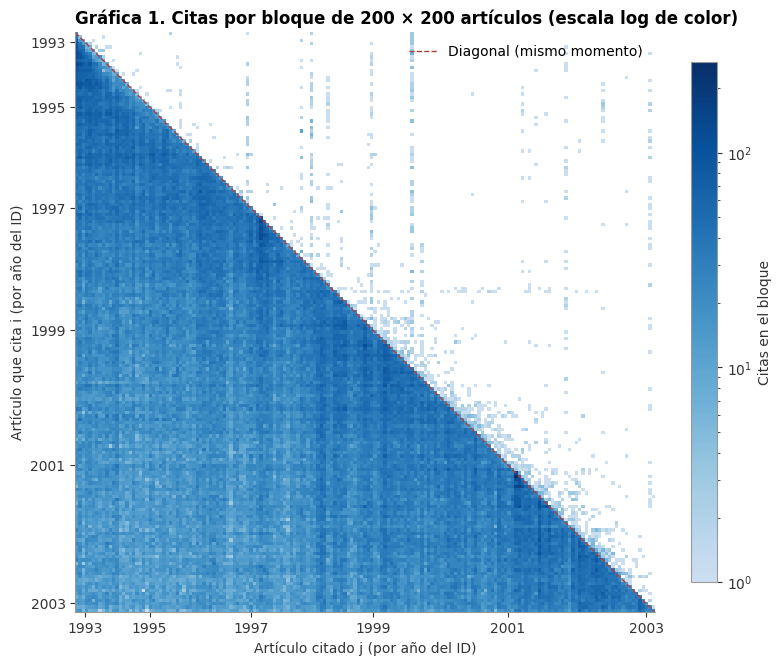

Entradas debajo de la diagonal (j anterior a i en el orden): 419,528 (99.52 %) | encima: 2,006 (0.48 %)
De las de encima, marcadas como cita al futuro: 1,824


In [4]:
# Gráfica 1. Patrón de la matriz de adyacencia por bloques, con los nodos en orden cronológico
bloque = 200
nb = int(np.ceil(n / bloque))
coo = A.tocoo()
conteo = np.zeros((nb, nb))
np.add.at(conteo, (coo.row // bloque, coo.col // bloque), 1)
conteo[conteo == 0] = np.nan

# Marcas de año sobre los ejes: primer índice de cada año
inicio_anio = nodos.groupby(nodos["mes_id"].dt.year).apply(lambda d: d.index.min())

fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(conteo, cmap=CMAP_SEC, norm=LogNorm(vmin=1, vmax=np.nanmax(conteo)), interpolation="nearest",
               extent=(0, n, n, 0))
ax.plot([0, n], [0, n], color=ROJO, linewidth=1, linestyle="--", label="Diagonal (mismo momento)")
ax.set_xticks(inicio_anio.to_numpy()[1::2], labels=inicio_anio.index[1::2])
ax.set_yticks(inicio_anio.to_numpy()[1::2], labels=inicio_anio.index[1::2])
estilo_ejes(ax, "Gráfica 1. Citas por bloque de 200 × 200 artículos (escala log de color)",
            "Artículo citado j (por año del ID)", "Artículo que cita i (por año del ID)", rejilla=None)
fig.colorbar(im, ax=ax, label="Citas en el bloque", shrink=0.82)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

abajo = (coo.col < coo.row).sum()
arriba = (coo.col > coo.row).sum()
print(f"Entradas debajo de la diagonal (j anterior a i en el orden): {abajo:,} ({pct(abajo / A.nnz)}) | "
      f"encima: {arriba:,} ({pct(arriba / A.nnz)})")
print(f"De las de encima, marcadas como cita al futuro: "
      f"{aristas.loc[columnas > filas, 'es_futuro'].sum():,}")

**Observaciones: matriz de adyacencia**

- **Tamaño.** $A$ es de **34,546 × 34,546** con **421,534** entradas distintas de cero, una densidad de **3.53e-04**.
  En CSR ocupa **5.2 MB**, contra **9.55 GB** de la versión densa en `float64`: **1,837 veces** menos.
- **Consistencia con el notebook 1.** Las sumas por fila y por columna de $A$ coinciden exactamente con `k_out` y `k_in`.
- **La matriz es casi triangular inferior (Gráfica 1).** Con los nodos en orden cronológico, el **99.52 %** de las
  entradas (**419,528**) queda debajo de la diagonal: el artículo citado es anterior al que cita. Encima quedan
  **2,006** (**0.48 %**), de las que **1,824** son citas al futuro. Las otras **182** son citas entre artículos del
  mismo mes que, en el orden por ID, quedan del otro lado.
- **Patrones visibles.**
  - La banda oscura junto a la diagonal indica que lo más citado es lo reciente.
  - Las rayas verticales indican artículos muy citados: en una columna, todos los que los citan.
  - Las rayas que suben **por encima** de la diagonal son artículos citados desde el pasado por versiones revisadas;
    son las citas al futuro que crean la SCC gigante.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Matriz de transición</span></div>


PageRank modela a un **lector aleatorio** que está en un artículo y salta a una de sus referencias al azar. Su
distribución de probabilidad $v$ sobre los artículos evoluciona como $v' = M v$, donde $M$ es la **matriz de transición**
estocástica **por columnas** (Leskovec, Rajaraman y Ullman, *Mining of Massive Datasets*, cap. 5):

$$M_{ji} = \begin{cases} 1 / k_{out}(i) & \text{si } i \to j, \\ 0 & \text{en otro caso,} \end{cases}
\qquad\text{es decir,}\qquad M = A^\top D_{out}^{-1},$$

con $D_{out}$ la matriz diagonal de grados de salida. La columna $i$ reparte la probabilidad del artículo $i$ en partes
iguales entre sus referencias, así que suma 1. El método de potencias converge a un único vector estacionario solo si
el paseo es **irreducible** y **aperiódico**, y en este grafo hay dos obstáculos:

- **Nodos colgantes** (*dead ends*). Un artículo sin referencias en el conjunto tiene una columna de ceros: el lector no
  tiene a dónde ir y la probabilidad "se fuga". $M$ queda **subestocástica** y $\sum_j v_j$ decrece con cada iteración.
- **Trampas de araña** (*spider traps*). Son conjuntos de nodos con enlaces entre sí pero ninguno hacia fuera. El lector
  entra y no sale, y la trampa acaba con toda la probabilidad. En el grafo de componentes fuertemente conexas son las
  componentes **sin aristas de salida** que tienen más de un nodo.

Hay dos remedios clásicos:

1. **Eliminar los nodos colgantes de forma recursiva** y calcular PageRank en lo que queda.
2. Los **impuestos** o **teletransportación**: con probabilidad $1 - \beta$ el lector salta a un artículo al azar,

   $$v' = \beta M v + (1 - \beta)\, \frac{e}{n},$$

   y desde un nodo colgante salta siempre al azar.

El remedio 2 resuelve los dos problemas a la vez y es el que aplica `networkx.pagerank`. Aquí se mide qué tan grave es
cada problema para justificarlo.

In [5]:
# Matriz de transición M = Aᵀ · D_out⁻¹ (estocástica por columnas) y nodos colgantes
k_out = np.asarray(A.sum(axis=1)).ravel()
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)
M = (A.T @ sp.diags(inv_k_out)).tocsc()

suma_columnas = np.asarray(M.sum(axis=0)).ravel()
colgantes = k_out == 0
print(f"Columnas de M que suman 1: {np.isclose(suma_columnas, 1).sum():,} | que suman 0 (colgantes): "
      f"{(suma_columnas == 0).sum():,} | otras: {(~np.isclose(suma_columnas, 1) & (suma_columnas != 0)).sum():,}")

# Fuga de probabilidad: método de potencias sin teletransportación, solo para medir cuánto se pierde
v = np.full(n, 1 / n)
masa = [v.sum()]
for _ in range(30):
    v = M @ v
    masa.append(v.sum())
print("Probabilidad total tras t pasos de v' = Mv, sin teletransportación:")
print(" | ".join(f"t = {t}: {masa[t]:.4f}" for t in [0, 1, 2, 5, 10, 20, 30]))

Columnas de M que suman 1: 32,153 | que suman 0 (colgantes): 2,393 | otras: 0
Probabilidad total tras t pasos de v' = Mv, sin teletransportación:
t = 0: 1.0000 | t = 1: 0.9307 | t = 2: 0.7793 | t = 5: 0.2326 | t = 10: 0.0075 | t = 20: 0.0001 | t = 30: 0.0001


In [6]:
# Gravedad de los dos problemas: eliminación recursiva de colgantes y trampas de araña
G = nx.from_scipy_sparse_array(A, create_using=nx.DiGraph)

H = G.copy()
rondas = []
while True:
    quitar = [v for v, k in H.out_degree() if k == 0]
    if not quitar:
        break
    H.remove_nodes_from(quitar)
    rondas.append(len(quitar))
print(f"Eliminación recursiva de colgantes: {len(rondas)} rondas, se quitan {n - H.number_of_nodes():,} nodos "
      f"({pct((n - H.number_of_nodes()) / n)}) y quedan {H.number_of_nodes():,}")
print(f"Nodos quitados por ronda: {rondas}")

C = nx.condensation(G)
tam = pd.Series({c: len(C.nodes[c]["members"]) for c in C})
sin_salida = pd.Series({c: C.out_degree(c) == 0 for c in C})
trampas = tam[sin_salida & (tam > 1)]
print(f"Componentes fuertemente conexas sin salida: {sin_salida.sum():,} "
      f"(de un nodo = colgantes: {(sin_salida & (tam == 1)).sum():,}; trampas de más de un nodo: {len(trampas)})")
for c in trampas.index:
    miembros = sorted(C.nodes[c]["members"])
    display(nodos.loc[miembros, ["id", "fecha", "mes_id", "k_in", "k_out"]])
    print("Aristas dentro de la trampa:",
          aristas[aristas["origen"].isin(nodos.loc[miembros, "id"]) & aristas["destino"].isin(nodos.loc[miembros, "id"])]
          [["origen", "destino", "es_reciproca", "es_futuro"]].to_dict("records"))

Eliminación recursiva de colgantes: 19 rondas, se quitan 9,656 nodos (27.95 %) y quedan 24,890
Nodos quitados por ronda: [2393, 1797, 1307, 1034, 899, 650, 448, 364, 298, 194, 137, 75, 35, 11, 4, 3, 4, 2, 1]


Componentes fuertemente conexas sin salida: 2,394 (de un nodo = colgantes: 2,393; trampas de más de un nodo: 1)


,id,fecha,mes_id,k_in,k_out
indice,,,,,
16916,9810372,1998-10-15,1998-10-01,1,1
16923,9810379,1998-10-16,1998-10-01,2,1


Aristas dentro de la trampa: [{'origen': '9810379', 'destino': '9810372', 'es_reciproca': True, 'es_futuro': False}, {'origen': '9810372', 'destino': '9810379', 'es_reciproca': True, 'es_futuro': True}]


In [7]:
# Guardado de A en .npz con el mapeo índice → ID, en el formato que lee scipy.sparse.load_npz
np.savez_compressed(ARCHIVO_MATRIZ, data=A.data, indices=A.indices, indptr=A.indptr, format=np.bytes_("csr"),
                    shape=np.array(A.shape), ids=nodos["id"].to_numpy().astype("U7"))

# Verificación: se vuelve a leer y se compara con lo que hay en memoria
A_leida = sp.load_npz(ARCHIVO_MATRIZ)
ids_leidos = np.load(ARCHIVO_MATRIZ)["ids"]
assert (A_leida != A).nnz == 0 and A_leida.format == "csr"
assert np.array_equal(ids_leidos, nodos["id"].to_numpy())
print(f"{ARCHIVO_MATRIZ.name}: {ARCHIVO_MATRIZ.stat().st_size / 1024:,.0f} KB | matriz {A_leida.shape}, "
      f"nnz = {A_leida.nnz:,} | ids[0:3] = {[str(i) for i in ids_leidos[:3]]}")

adyacencia.npz: 980 KB | matriz (34546, 34546), nnz = 421,534 | ids[0:3] = ['9203201', '9203202', '9203203']


**Observaciones y decisión: matriz de transición**

- **Columnas de $M$.** **32,153** suman 1 y las **2,393** de los nodos colgantes suman 0. $M$ es subestocástica.
- **La fuga es rápida.** Con $v' = Mv$ sin teletransportación, la probabilidad total pasa de 1 a:
  - **0.9307** en un paso, que es justo la masa de los colgantes;
  - **0.2326** en 5 pasos y **0.0075** en 10;
  - **0.0001** en 20, que **ya no baja** en el paso 30. Lo que queda está atrapado en la trampa de araña.
- **Eliminar los colgantes de forma recursiva no es viable.** Como el grafo es casi acíclico, al quitar los colgantes
  aparecen otros nuevos: son **19** rondas (**2,393**, **1,797**, **1,307**…) que quitan **9,656** nodos (**27.95 %**).
  Además, los colgantes son sobre todo los artículos **más viejos**, que no tienen a quién citar dentro del conjunto,
  y entre ellos hay muy citados (`9203203`, de marzo de 1992, tiene **217** citas). Quitarlos borraría justo a los
  artículos que PageRank debería poner arriba.
- **Hay exactamente una trampa de araña.** Es la pareja `9810372` ↔ `9810379`, enviada el 15 y el 16 de octubre de
  1998, en la que cada artículo tiene una sola referencia: el otro. Una de las dos aristas es una cita al futuro.
  Fuera de ella, todas las componentes sin salida son nodos colgantes.

**Decisión: PageRank con teletransportación, sin eliminar nodos.** Es el remedio que corrige los dos problemas a la
vez y el que implementa `networkx.pagerank`. Por defecto (`dangling=None`), la probabilidad que llega a un nodo
colgante se reparte de manera uniforme, igual que el salto aleatorio. La matriz $A$ queda guardada con su mapeo de IDs
en `data/processed/adyacencia.npz` (**980 KB**). El notebook 3 la vuelve a leer y comprueba que coincida con
`nodos_limpios.parquet`.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Grafo de análisis: sin citas al futuro</span></div>


**Decisión.** El análisis principal de este notebook (PageRank, su ajuste por cohorte y HITS) y el PageRank sensible a
tópico del notebook 3 se hacen sobre el grafo **sin citas al futuro**. Las aristas no se borran de los datos: se excluyen
con la marca `es_futuro` del notebook 1. La comparación con el grafo completo queda como sección de robustez (4.4).

**Una sola definición de `es_futuro`.** Es la columna de `aristas_limpias.parquet`, tal como se definió en la sección 5
del notebook 1: una arista *i → j* es una cita al futuro si el citado es posterior al que cita, medido en **días**
cuando las dos fechas existen y, si falta alguna, en **meses** de `mes_id`. No hay que confundirla con `es_reciproca`
(pares *i ↔ j*), que es otra marca. La celda siguiente muestra el desglose y el cruce entre las dos.

**Por qué.** En una red de citas solo se puede citar hacia el pasado, y la sección 4.4 muestra que estas 1,852 aristas
(0.44 %) bastan para colocar en el top-100 de PageRank a artículos que, sin ellas, quedan fuera del top-1,000.

In [8]:
# Desglose de es_futuro (definición del notebook 1) y cruce con es_reciproca
es_futuro = aristas["es_futuro"].to_numpy()
por_dias = (aristas["desfase_dias"] > 0).fillna(False).to_numpy()
por_mes = (aristas["desfase_dias"].isna() & (aristas["desfase_meses_id"] > 0)).to_numpy()
assert np.array_equal(es_futuro, por_dias | por_mes)

desglose = pd.Series({
    "Aristas": f"{len(aristas):,}",
    "es_futuro (total)": f"{es_futuro.sum():,} ({pct(es_futuro.mean(), 3)})",
    "   · por desfase en días (las dos fechas)": f"{por_dias.sum():,}",
    "   · por desfase de mes_id (falta alguna fecha)": f"{por_mes.sum():,}",
    "es_reciproca (otra marca: pares i ↔ j)": f"{aristas['es_reciproca'].sum():,}",
    "   · recíprocas que además son al futuro": f"{(aristas['es_reciproca'] & aristas['es_futuro']).sum():,}",
}, name="Aristas").rename_axis("Marca").to_frame()
display(desglose)

,Aristas
Marca,
Aristas,"421,534"
es_futuro (total),"1,852 (0.439 %)"
· por desfase en días (las dos fechas),"1,584"
· por desfase de mes_id (falta alguna fecha),268
es_reciproca (otra marca: pares i ↔ j),"1,314"
· recíprocas que además son al futuro,550


In [9]:
# Grafo sin citas al futuro: SCC mayor, nodos colgantes y trampas de araña, comparados con el grafo completo
A_sf = sp.csr_matrix((np.ones((~es_futuro).sum()), (filas[~es_futuro], columnas[~es_futuro])), shape=(n, n))
G_sf = nx.from_scipy_sparse_array(A_sf, create_using=nx.DiGraph)


def resumen_grafo(grafo, matriz):
    """
    Resume la estructura de un grafo de citas: aristas, SCC mayor, ciclos, nodos colgantes y trampas de araña.

    Parámetros
    ----------
    grafo : nx.DiGraph
        Grafo con nodos 0..n-1.
    matriz : scipy.sparse.csr_matrix
        Su matriz de adyacencia.

    Retorna
    -------
    pd.Series
        Indicadores estructurales.
    """
    tam = sorted((len(c) for c in nx.strongly_connected_components(grafo)), reverse=True)
    cond = nx.condensation(grafo)
    trampas = sum(1 for c in cond if cond.out_degree(c) == 0 and len(cond.nodes[c]["members"]) > 1)
    return pd.Series({"aristas": f"{matriz.nnz:,}", "SCC mayor (nodos)": f"{tam[0]:,}",
                      "SCC con más de un nodo": sum(t > 1 for t in tam),
                      "nodos colgantes": f"{(np.asarray(matriz.sum(axis=1)).ravel() == 0).sum():,}",
                      "trampas de araña": trampas})


display(pd.DataFrame({"grafo completo": resumen_grafo(G, A), "sin citas al futuro": resumen_grafo(G_sf, A_sf)}))

# A partir de aquí, k_in, k_out y es_colgante se refieren al grafo de análisis; los del grafo completo se conservan
nodos["k_in_completo"], nodos["k_out_completo"] = nodos["k_in"], nodos["k_out"]
nodos["k_in"] = np.asarray(A_sf.sum(axis=0)).ravel().astype(int)
nodos["k_out"] = np.asarray(A_sf.sum(axis=1)).ravel().astype(int)
nodos["es_colgante"] = nodos["k_out"] == 0
print(f"Nodos que se vuelven colgantes al quitar las citas al futuro: "
      f"{(nodos['es_colgante'] & (nodos['k_out_completo'] > 0)).sum():,}")

,grafo completo,sin citas al futuro
aristas,"421,534","419,682"
SCC mayor (nodos),"12,711",4
SCC con más de un nodo,143,95
nodos colgantes,"2,393","2,460"
trampas de araña,1,0


Nodos que se vuelven colgantes al quitar las citas al futuro: 67


**Observaciones: grafo de análisis**

- **Una sola definición.** `es_futuro` marca **1,852** aristas (**0.439 %**): **1,584** detectadas por desfase en días y
  **268** por `mes_id`, cuando falta alguna fecha. Es la columna del notebook 1 sin cambios (la celda lo comprueba con un
  `assert`). Las **1,314** de `es_reciproca` son otra marca. **550** aristas tienen las dos; en el notebook 1 eran 466
  porque ahí se contaban solo las que tienen las dos fechas.
- **Los ciclos vienen de las citas al futuro.** Sin ellas, la SCC mayor pasa de **12,711** nodos a **4**. Las SCC con
  más de un nodo bajan de **143** a **95**; son ciclos pequeños entre artículos del mismo mes.
- **Grafo de análisis.** Tiene **419,682** aristas y **2,460** nodos colgantes: **67** más, porque todas sus referencias
  eran al futuro. La única trampa de araña desaparece (**1 → 0**), porque una de sus dos aristas era una cita al futuro.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. PageRank</span></div>


**Grafo.** Todo el análisis de esta sección usa el grafo **sin citas al futuro** (sección 3.1), `G_sf`.

**Qué calcula.** `networkx.pagerank(G, alpha=β)` encuentra el vector estacionario del paseo aleatorio con
teletransportación de la sección 3:

$$v' = \beta M v + (1 - \beta)\,\frac{e}{n}, \qquad \sum_i v_i = 1,$$

con el método de potencias: parte de $v_0 = e/n$ y repite la iteración hasta que $\lVert v_{t+1} - v_t \rVert_1 < n \cdot
\texttt{tol}$. $\beta$ es la probabilidad de seguir una referencia y $1 - \beta$ la de saltar a un artículo al azar.

**Nodos colgantes (`dangling`).** Con `dangling=None`, en cada iteración la probabilidad acumulada en los colgantes,
$\sum_{i:\,k_{out}(i)=0} v_i$, se reparte entre todos los nodos con el mismo vector de teletransportación (uniforme,
salvo que se pase `personalization`). Equivale a reemplazar cada columna de ceros de $M$ por $e/n$. Así $M$ se vuelve
estocástica y el vector suma 1 en cada paso, sin eliminar ningún nodo.

**Tolerancia.** El criterio de parada de `networkx` escala con $n$: con el valor por defecto (`tol=1e-6`) se detiene
cuando la diferencia L1 es menor que $34{,}546 \times 10^{-6} \approx 0.035$, demasiado holgado para comparar rankings
finos. Se usa `tol=1e-10`. **Iteraciones:** `networkx` no las reporta, así que se miden buscando el menor `max_iter`
con el que la función no lanza `PowerIterationFailedConvergence` (búsqueda binaria; el algoritmo no se reimplementa).

**Valores de β.** El valor estándar es 0.85 y se compara con 0.70 y 0.95. Con un β mayor se siguen cadenas de citas
más largas antes de teletransportarse.

In [10]:
# PageRank con networkx para tres valores de β, con el número de iteraciones hasta converger
import time

from scipy.stats import kendalltau, spearmanr

BETAS = [0.70, 0.85, 0.95]
TOL = 1e-10


def pagerank(grafo, beta, **kwargs):
    """
    Calcula PageRank con networkx y lo devuelve como Serie ordenada por índice de nodo.

    Parámetros
    ----------
    grafo : nx.DiGraph
        Grafo con nodos 0..n-1.
    beta : float
        Probabilidad de seguir un enlace (`alpha` en networkx).
    **kwargs
        Argumentos adicionales para `nx.pagerank` (por ejemplo, `personalization`).

    Retorna
    -------
    pd.Series
        Puntaje de cada nodo; suma 1.
    """
    pr = nx.pagerank(grafo, alpha=beta, tol=TOL, max_iter=1000, **kwargs)
    return pd.Series(pr).sort_index()


def iteraciones_pagerank(grafo, beta, max_busqueda=1000, **kwargs):
    """
    Encuentra el menor número de iteraciones con el que nx.pagerank converge (búsqueda binaria sobre max_iter).

    Parámetros
    ----------
    grafo : nx.DiGraph
        Grafo dirigido.
    beta : float
        Probabilidad de seguir un enlace.
    max_busqueda : int
        Cota superior de la búsqueda.
    **kwargs
        Argumentos adicionales para `nx.pagerank`.

    Retorna
    -------
    int
        Iteraciones necesarias con la tolerancia TOL.
    """
    lo, hi = 1, max_busqueda
    while lo < hi:
        medio = (lo + hi) // 2
        try:
            nx.pagerank(grafo, alpha=beta, tol=TOL, max_iter=medio, **kwargs)
            hi = medio
        except nx.PowerIterationFailedConvergence:
            lo = medio + 1
    return lo


pr = {}
filas_pr = []
for beta in BETAS:
    t0 = time.perf_counter()
    pr[beta] = pagerank(G_sf, beta)
    segundos = time.perf_counter() - t0
    top = pr[beta].idxmax()
    filas_pr.append({"β": beta, "iteraciones": iteraciones_pagerank(G_sf, beta), "segundos": round(segundos, 2),
                     "suma": round(pr[beta].sum(), 10), "máximo": pr[beta].max(),
                     "mínimo": pr[beta].min(), "máximo / mínimo": round(pr[beta].max() / pr[beta].min(), 1),
                     "top 1": nodos.loc[top, "id"]})
display(pd.DataFrame(filas_pr).set_index("β"))

,iteraciones,segundos,suma,máximo,mínimo,máximo / mínimo,top 1
β,,,,,,,
0.70,13,0.73,1.0,0.002810,0.000012,230.8,9303255
0.85,16,0.66,1.0,0.004163,0.000009,442.4,9303255
0.95,18,0.69,1.0,0.005241,0.000008,673.0,9303255


In [11]:
# Top 20 de PageRank con β = 0.85, junto a su lugar por número de citas recibidas
def tabla_top(puntaje, k=20, nombre="PageRank"):
    """
    Arma la tabla de los k nodos con mayor puntaje, con sus datos y su lugar por grado de entrada.

    Parámetros
    ----------
    puntaje : pd.Series
        Puntaje por índice de nodo.
    k : int
        Número de nodos.
    nombre : str
        Nombre de la columna del puntaje.

    Retorna
    -------
    pd.DataFrame
        Lugar, ID, fecha, año, grados, puntaje y lugar por k_in.
    """
    lugar_kin = nodos["k_in"].rank(ascending=False, method="min").astype(int)
    top = puntaje.nlargest(k).index
    return pd.DataFrame({
        "id": nodos.loc[top, "id"].to_numpy(), "año": nodos.loc[top, "anio_id"].to_numpy(),
        "k_in": nodos.loc[top, "k_in"].to_numpy(), "k_out": nodos.loc[top, "k_out"].to_numpy(),
        nombre: puntaje.loc[top].round(6).to_numpy(), "lugar por k_in": lugar_kin.loc[top].to_numpy(),
    }, index=pd.RangeIndex(1, k + 1, name="lugar"))


top20_85 = tabla_top(pr[0.85])
display(top20_85)
print(f"Top-20: años {top20_85['año'].value_counts().sort_index().to_dict()} | colgantes (k_out = 0): "
      f"{(top20_85['k_out'] == 0).sum()} | con menos de 50 citas: {(top20_85['k_in'] < 50).sum()}")

,id,año,k_in,k_out,PageRank,lugar por k_in
lugar,,,,,,
1,9303255,1993,154,0,0.004163,168
2,9209205,1992,343,0,0.002751,16
3,9206203,1992,32,0,0.002245,3234
4,9208254,1992,67,0,0.002119,1075
5,9206242,1992,140,0,0.001868,205
6,9803315,1998,846,0,0.001832,1
7,9203203,1992,217,0,0.001731,74
8,9303230,1993,347,1,0.001642,15
9,9206236,1992,122,0,0.001576,284


Top-20: años {1992: 14, 1993: 3, 1994: 2, 1998: 1} | colgantes (k_out = 0): 15 | con menos de 50 citas: 2


**Observaciones: PageRank**

- **Convergencia.** Con `tol=1e-10`, PageRank converge en **13**, **16** y **18** iteraciones para $\beta$ = 0.70,
  0.85 y 0.95, en alrededor de un segundo cada vez. Converge rápido porque, sin ciclos, las cadenas de citas son cortas
  y la probabilidad recorre todo el grafo en pocos pasos. Los vectores suman **1.0**.
- **Concentración.** El cociente entre el puntaje máximo y el mínimo es **230.8**, **442.4** y **673.0**: con un $\beta$
  mayor se teletransporta menos y la probabilidad se concentra más.
- **El nº 1 es el mismo con los tres $\beta$:** `9303255` (1993), con **154** citas, el lugar **168** por citas recibidas.
- **El top-20 es de artículos viejos y colgantes.** Hay **14** de 1992, **3** de 1993, **2** de 1994 y **1** de 1998, y
  **15** de los 20 no citan a nadie del conjunto ($k_{out} = 0$). Al no tener referencias, no reparten su puntaje: lo que
  les llega solo vuelve al resto por la teletransportación. **2** de ellos tienen menos de 50 citas. Por ejemplo,
  `9206203` es 3.º con **32** citas (lugar **3,234** por citas).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.1 Sensibilidad a β</span></div>


Se compara qué tanto cambia el ranking entre los tres valores de $\beta$ con dos tipos de medida:

- **Traslape del top-k:** el índice de Jaccard $|T_a \cap T_b| / |T_a \cup T_b|$ entre los $k$ primeros de cada
  ranking. Mide la estabilidad de "los más importantes".
- **Correlación de rangos** sobre los 34,546 nodos: la $\tau$ de Kendall (proporción de pares en el mismo orden menos
  pares invertidos) y la $\rho$ de Spearman (correlación de Pearson entre los lugares). Miden la estabilidad del
  ranking completo.

,Jaccard top-20,Jaccard top-100,Kendall τ,Spearman ρ
par de β,,,,
0.70 vs 0.85,0.739,0.961,0.9838,0.9995
0.85 vs 0.95,0.905,0.887,0.9895,0.9998
0.70 vs 0.95,0.667,0.852,0.9733,0.9987


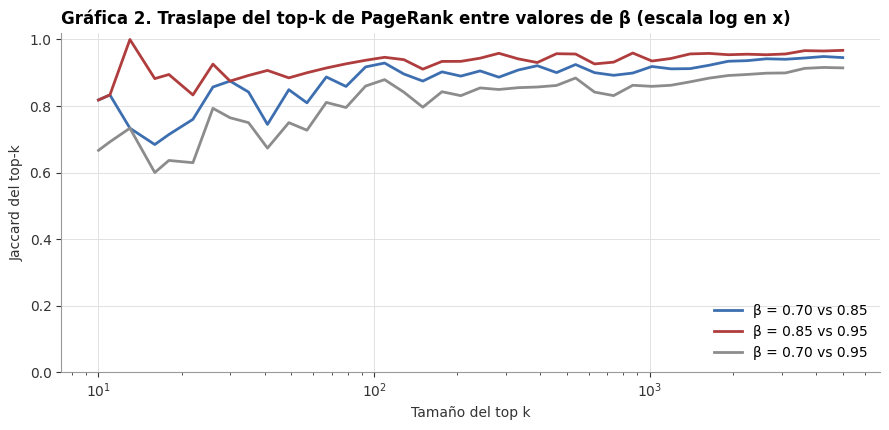

Top 10 con cada β:


,β = 0.70,β = 0.85,β = 0.95
lugar,,,
1,9303255,9303255,9303255
2,9209205,9209205,9209205
3,9803315,9206203,9206203
4,9206203,9208254,9208254
5,9208254,9206242,9206242
6,9203203,9803315,9303230
7,9206242,9203203,9205227
8,9404270,9303230,9803315
9,9207214,9206236,9203203


In [12]:
# Jaccard del top-20 y del top-100, y correlaciones de Kendall y Spearman entre pares de β
def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : pd.Series
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = set(a.nlargest(k).index), set(b.nlargest(k).index)
    return len(ta & tb) / len(ta | tb)


pares = [(0.70, 0.85), (0.85, 0.95), (0.70, 0.95)]
sensibilidad = pd.DataFrame([{
    "par de β": f"{a:.2f} vs {b:.2f}",
    "Jaccard top-20": round(jaccard_top(pr[a], pr[b], 20), 3),
    "Jaccard top-100": round(jaccard_top(pr[a], pr[b], 100), 3),
    "Kendall τ": round(kendalltau(pr[a], pr[b]).statistic, 4),
    "Spearman ρ": round(spearmanr(pr[a], pr[b]).statistic, 4),
} for a, b in pares]).set_index("par de β")
display(sensibilidad)

# Gráfica 2. Jaccard del top-k en función de k
ks = np.unique(np.logspace(1, np.log10(5000), 40).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.4))
for (a, b), color in zip(pares, [AZUL, ROJO, GRIS]):
    ax.plot(ks, [jaccard_top(pr[a], pr[b], k) for k in ks], color=color, linewidth=2, label=f"β = {a:.2f} vs {b:.2f}")
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
estilo_ejes(ax, "Gráfica 2. Traslape del top-k de PageRank entre valores de β (escala log en x)",
            "Tamaño del top k", "Jaccard del top-k", rejilla="both")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

top20 = pd.DataFrame({f"β = {b:.2f}": nodos.loc[pr[b].nlargest(10).index, "id"].to_numpy() for b in BETAS},
                     index=pd.RangeIndex(1, 11, name="lugar"))
print("Top 10 con cada β:")
display(top20)

**Observaciones: sensibilidad a β**

- **El ranking completo casi no depende de $\beta$:** Spearman $\rho \ge$ **0.9987** y Kendall $\tau$ entre **0.9733** y
  **0.9895** para los tres pares.
- **El top-k sí se mueve.** El Jaccard del top-20 es **0.739** (0.70 contra 0.85), **0.905** (0.85 contra 0.95) y
  **0.667** (0.70 contra 0.95); el del top-100, **0.961**, **0.887** y **0.852**. En la Gráfica 2 el traslape oscila
  mucho para $k$ pequeños, donde un solo cambio pesa, y a partir de unos cientos de nodos se estabiliza alrededor de 0.85 o más.
- **Cómo cambia el orden.** Los dos primeros (`9303255` y `9209205`) no cambian. El más citado del conjunto, `9803315`
  (1998), está 3.º con $\beta$ = 0.70, 6.º con 0.85 y 8.º con 0.95.
  - Con $\beta$ bajo domina la teletransportación y PageRank se parece más a contar citas directas.
  - Con $\beta$ alto pesan las cadenas largas de citas, que terminan en los artículos más viejos.
- **Decisión:** se usa $\beta$ = **0.85**, el valor estándar, que queda entre los dos extremos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.2 ¿PageRank es solo contar citas?</span></div>


Si PageRank solo contara citas, su ranking sería igual al del grado de entrada $k_{in}$. La diferencia es que en
PageRank **una cita vale lo que vale quien cita, dividido entre su número de referencias**: $v_j = \beta \sum_{i \to j}
v_i / k_{out}(i) + (1-\beta)/n$. Se compara la distribución de los puntajes con la de $k_{in}$ y se buscan los
artículos en los que los dos rankings más difieren.

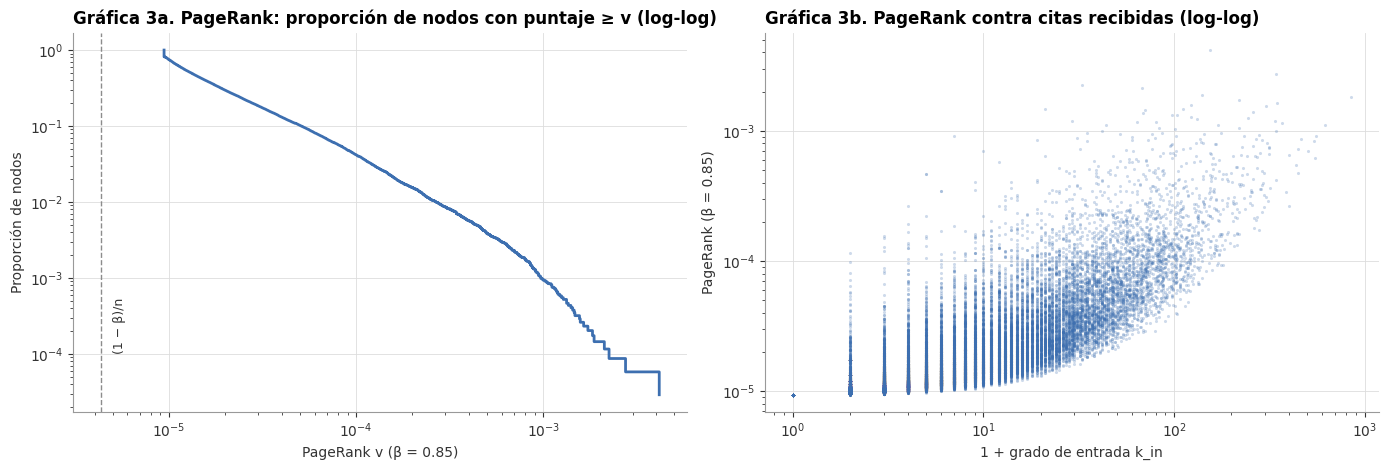

PageRank mínimo: 9.412e-06 | (1 − β)/n = 4.342e-06 | nodos con el mínimo (k_in = 0): 6,368
Spearman ρ(PageRank, k_in) = 0.9104 | Jaccard top-100 PageRank vs k_in = 0.212 | top-20: 0.081


In [13]:
# Gráfica 3. Distribución de PageRank (log-log) y PageRank contra grado de entrada
pr85 = pr[0.85]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
v = np.sort(pr85.to_numpy())
ax1.step(v, 1 - np.arange(len(v)) / len(v), where="post", color=AZUL, linewidth=2)
ax1.axvline((1 - 0.85) / n, color=GRIS, linestyle="--", linewidth=1)
ax1.text((1 - 0.85) / n * 1.15, 1e-4, "(1 − β)/n", fontsize=9, color=TINTA, rotation=90, va="bottom")
ax1.set_xscale("log")
ax1.set_yscale("log")
estilo_ejes(ax1, "Gráfica 3a. PageRank: proporción de nodos con puntaje ≥ v (log-log)", "PageRank v (β = 0.85)",
            "Proporción de nodos", rejilla="both")

ax2.scatter(nodos["k_in"] + 1, pr85, s=5, color=AZUL, alpha=0.25, linewidths=0)
ax2.set_xscale("log")
ax2.set_yscale("log")
estilo_ejes(ax2, "Gráfica 3b. PageRank contra citas recibidas (log-log)", "1 + grado de entrada k_in",
            "PageRank (β = 0.85)", rejilla="both")
plt.tight_layout()
plt.show()

rho_kin = spearmanr(pr85, nodos["k_in"]).statistic
print(f"PageRank mínimo: {pr85.min():.3e} | (1 − β)/n = {(1 - 0.85) / n:.3e} | "
      f"nodos con el mínimo (k_in = 0): {(np.isclose(pr85, pr85.min())).sum():,}")
print(f"Spearman ρ(PageRank, k_in) = {rho_kin:.4f} | Jaccard top-100 PageRank vs k_in = "
      f"{jaccard_top(pr85, nodos['k_in'].astype(float), 100):.3f} | top-20: {jaccard_top(pr85, nodos['k_in'].astype(float), 20):.3f}")

In [14]:
# Artículos con mayor diferencia entre su lugar en PageRank y su lugar por citas recibidas
lugar_pr = pr85.rank(ascending=False, method="min")
lugar_kin = nodos["k_in"].rank(ascending=False, method="min")
comparacion = pd.DataFrame({"id": nodos["id"], "año": nodos["anio_id"], "k_in": nodos["k_in"], "k_out": nodos["k_out"],
                            "lugar PageRank": lugar_pr.astype(int), "lugar k_in": lugar_kin.astype(int)})
comparacion["suben (lugares)"] = comparacion["lugar k_in"] - comparacion["lugar PageRank"]
top500 = comparacion[comparacion["lugar PageRank"] <= 500]
print("Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:")
display(top500.nlargest(6, "suben (lugares)"))
print("Dentro del top-500 por k_in, los que más bajan en PageRank:")
display(comparacion[comparacion["lugar k_in"] <= 500].nsmallest(6, "suben (lugares)"))

# Calidad de quien cita: PageRank medio de los citantes, para el que más sube y el que más baja
for etiqueta, fila in [("sube", top500.nlargest(1, "suben (lugares)").index[0]),
                       ("baja", comparacion[comparacion["lugar k_in"] <= 500].nsmallest(1, "suben (lugares)").index[0])]:
    citantes = A_sf[:, fila].nonzero()[0]
    print(f"{etiqueta}: {nodos.loc[fila, 'id']} | citantes: {len(citantes)} | PageRank mediano de sus citantes: "
          f"{np.median(pr85.to_numpy()[citantes]):.2e} | k_out mediano de sus citantes: "
          f"{np.median(nodos['k_out'].to_numpy()[citantes]):.0f}")
print(f"Referencia: PageRank mediano de todo el grafo {pr85.median():.2e} | k_out mediano de los que citan algo "
      f"{nodos.loc[nodos['k_out'] > 0, 'k_out'].median():.0f}")

Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:


,id,año,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
1253,9307225,1993,3,0,347,18466,18119
2129,9401216,1994,4,5,156,16516,16360
1333,9307327,1993,4,0,159,16516,16357
418,9211230,1992,4,0,457,16516,16059
58,9205204,1992,5,0,241,14955,14714
1530,9309204,1993,5,0,252,14955,14703


Dentro del top-500 por k_in, los que más bajan en PageRank:


,id,año,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
26516,0103067,2001,103,53,4643,425,-4218
26435,0102331,2001,102,68,4523,438,-4085
24655,0010003,2000,113,15,3949,344,-3605
26311,0102204,2001,100,20,3896,467,-3429
26254,0102147,2001,98,14,3879,491,-3388
24632,0009337,2000,118,34,3630,305,-3325


sube: 9307225 | citantes: 3 | PageRank mediano de sus citantes: 8.85e-05 | k_out mediano de sus citantes: 1
baja: 0103067 | citantes: 103 | PageRank mediano de sus citantes: 1.13e-05 | k_out mediano de sus citantes: 42
Referencia: PageRank mediano de todo el grafo 1.31e-05 | k_out mediano de los que citan algo 9


**Observaciones: PageRank contra citas**

- **Se parecen en conjunto, pero no arriba.** La correlación de rangos es alta (Spearman $\rho$ = **0.9104**), pero el
  traslape del top-20 con el top-20 por citas es de apenas **0.081** y el del top-100, **0.212**. PageRank no es contar
  citas, sobre todo donde importa.
- **Distribución (Gráfica 3a).** Tiene una cola pesada, casi recta en log-log. El mínimo (**9.412e-06**) es mayor que
  $(1-\beta)/n$ = **4.342e-06**, porque además del salto aleatorio cada nodo recibe su parte de la probabilidad de los
  colgantes. **6,368** nodos tienen ese mínimo: nadie los cita.
- **Mismas citas, puntajes distintos (Gráfica 3b).** Para un mismo $k_{in}$, el PageRank varía más de un orden de
  magnitud. La diferencia está en **quién** cita:
  - **Sube** `9307225` (1993). Con solo **3** citas es el **347** en PageRank (el **18,466** por citas). Sus citantes
    tienen un PageRank mediano de **8.85e-05**, contra **1.31e-05** de todo el grafo, y una sola referencia cada uno
    (mediana de $k_{out}$ = **1**): le pasan todo su puntaje.
  - **Baja** `0103067` (2001). Con **103** citas es el **4,643** en PageRank (el **425** por citas). Sus citantes tienen
    un PageRank mediano de **1.13e-05**, por debajo de la mediana global, y **42** referencias cada uno (la mediana
    general es **9**): cada cita le aporta poco.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.3 Sesgo por antigüedad</span></div>


En una red de citas las aristas apuntan hacia el pasado (99.52 % debajo de la diagonal, Gráfica 1), así que el paseo
aleatorio avanza **hacia atrás en el tiempo** y la probabilidad se acumula en los artículos viejos. Además, el notebook 1
mostró la censura hacia adelante: un artículo de 2002 tuvo meses para ser citado y uno de 1993, diez años. Comparar el
PageRank de artículos de años distintos mezcla calidad con edad.

**Ajuste propuesto:** comparar a cada artículo **dentro de su cohorte** (año de `mes_id`) con dos medidas:

- **percentil en la cohorte:** la proporción de artículos de su mismo año con PageRank menor o igual;
- **PageRank relativo:** $v_i / \operatorname{mediana}\{v_j : \text{año}(j) = \text{año}(i)\}$. A diferencia del percentil,
  conserva cuánto se separa del resto el mejor de cada año.

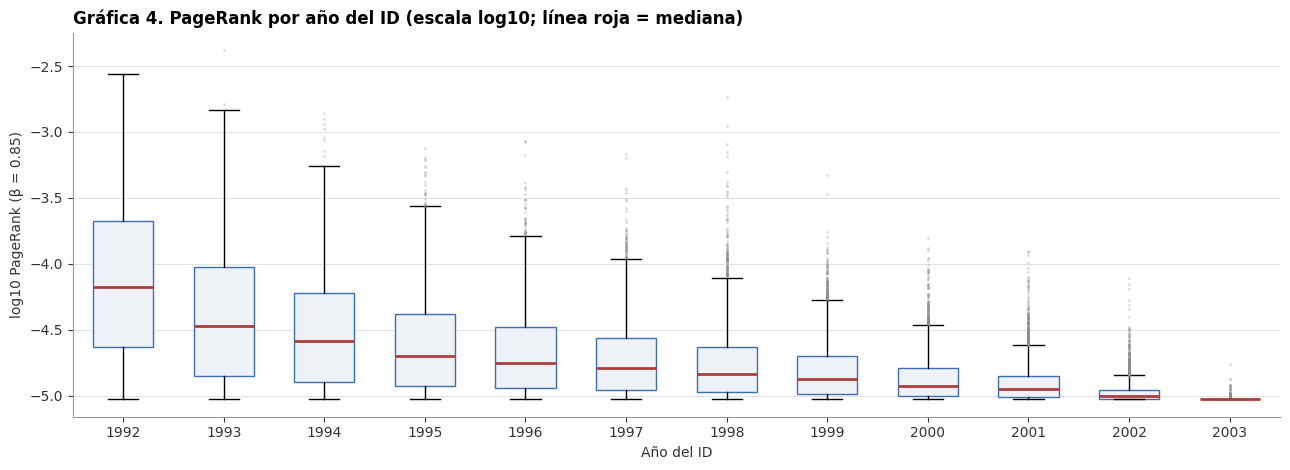

anio_id,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
artículos,582,1533,2308,2853,3202,3535,3723,4003,4025,4113,4137,532
PageRank mediano,6.69e-05,3.39e-05,2.61e-05,2.01e-05,1.78e-05,1.62e-05,1.45e-05,1.34e-05,1.19e-05,1.12e-05,9.89e-06,9.41e-06
% del PageRank total,11.1 %,14.1 %,12.2 %,11.1 %,9.8 %,8.8 %,9.0 %,7.3 %,6.0 %,5.5 %,4.5 %,0.5 %
artículos en el top-100,47,31,8,4,3,2,5,0,0,0,0,0


Spearman ρ(PageRank, año del ID) = -0.4729


In [15]:
# Gráfica 4. PageRank por año del ID y ajuste por cohorte
anio = nodos["anio_id"]
anios = sorted(anio.unique())
fig, ax = plt.subplots(figsize=(13, 4.8))
caja = ax.boxplot([np.log10(pr85[anio == a]) for a in anios], positions=anios, widths=0.6, patch_artist=True,
                  showfliers=True, flierprops=dict(marker=".", markersize=2, alpha=0.3, markeredgecolor=GRIS),
                  medianprops=dict(color=ROJO, linewidth=2))
for parche in caja["boxes"]:
    parche.set(facecolor=GRIS_CLARO, edgecolor=AZUL)
ax.set_xticks(anios, labels=anios)
estilo_ejes(ax, "Gráfica 4. PageRank por año del ID (escala log10; línea roja = mediana)", "Año del ID",
            "log10 PageRank (β = 0.85)")
plt.tight_layout()
plt.show()

por_anio = pd.DataFrame({"artículos": anio.value_counts().sort_index(),
                         "PageRank mediano": pr85.groupby(anio).median(),
                         "% del PageRank total": pr85.groupby(anio).sum().map(lambda x: pct(x, 1)),
                         "artículos en el top-100": anio[pr85.nlargest(100).index].value_counts()}).fillna(0)
por_anio["artículos en el top-100"] = por_anio["artículos en el top-100"].astype(int)
por_anio["PageRank mediano"] = por_anio["PageRank mediano"].map(lambda x: f"{x:.2e}")
display(por_anio.T)
print(f"Spearman ρ(PageRank, año del ID) = {spearmanr(pr85, anio).statistic:.4f}")

In [16]:
# Ajuste por cohorte: percentil dentro del año y PageRank relativo a la mediana del año
nodos["pagerank"] = pr85
nodos["percentil_cohorte"] = pr85.groupby(anio).rank(pct=True, method="max")
nodos["pagerank_relativo"] = pr85 / pr85.groupby(anio).transform("median")

# Solo se comparan cohortes completas: 1992 empieza en marzo y 2003 solo tiene enero y febrero
completas = nodos["anio_id"].between(1993, 2002)
top_rel = nodos[completas].nlargest(100, "pagerank_relativo")
top_crudo = nodos[completas].nlargest(100, "pagerank")
distribucion = pd.DataFrame({"top-100 PageRank crudo": top_crudo["anio_id"].value_counts(),
                             "top-100 PageRank relativo": top_rel["anio_id"].value_counts()}).reindex(range(1993, 2003)).fillna(0).astype(int)
display(distribucion.T)
print(f"Jaccard top-100 crudo vs relativo (1993–2002): "
      f"{len(set(top_rel.index) & set(top_crudo.index)) / len(set(top_rel.index) | set(top_crudo.index)):.3f}")
print("El mejor de cada cohorte según el PageRank relativo:")
mejores = nodos[completas].loc[nodos[completas].groupby("anio_id")["pagerank_relativo"].idxmax()]
display(mejores[["anio_id", "id", "k_in", "pagerank", "pagerank_relativo"]]
        .assign(lugar_global=lambda d: pr85.rank(ascending=False, method="min").loc[d.index].astype(int))
        .set_index("anio_id").round({"pagerank": 6, "pagerank_relativo": 1}))

anio_id,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002
top-100 PageRank crudo,57,21,10,3,2,6,1,0,0,0
top-100 PageRank relativo,34,19,13,9,7,16,2,0,0,0


Jaccard top-100 crudo vs relativo (1993–2002): 0.600
El mejor de cada cohorte según el PageRank relativo:


,id,k_in,pagerank,pagerank_relativo,lugar_global
anio_id,,,,,
1993,9303255,154,0.004163,122.9,1
1994,9404270,259,0.001405,53.8,14
1995,9502336,258,0.000760,37.8,65
1996,9610451,287,0.000856,48.2,51
1997,9711395,283,0.000678,41.8,82
1998,9803315,846,0.001832,126.3,6
1999,9905221,448,0.000470,35.1,152
2000,0009350,172,0.000156,13.1,748
2001,0106258,181,0.000125,11.2,1041


**Observaciones y decisión: sesgo por antigüedad**

- **El sesgo es fuerte (Gráfica 4).** El PageRank mediano baja de forma monótona de **6.69e-05** (1992) a **9.89e-06**
  (2002), y $\rho$(PageRank, año) = **−0.4729**.
  - Los **582** artículos de 1992 concentran el **11.1 %** del PageRank total; los **4,137** de 2002, el **4.5 %**.
  - En el top-100 hay **47** artículos de 1992, **31** de 1993 y **ninguno** de 1999 en adelante.

  Es la suma del flujo hacia el pasado (Gráfica 1) y de la censura hacia adelante del notebook 1.
- **El ajuste por cohorte ayuda, pero no lo elimina.** Sobre las cohortes completas (1993–2002), el top-100 por PageRank
  relativo reparte mejor los años:
  - 1998 pasa de **6** a **16** artículos y 1996 de **3** a **9**;
  - 1993 baja de **57** a **34**;
  - el Jaccard con el top-100 crudo es **0.600**.

  Aun así, de 2000 a 2002 sigue sin haber ninguno en el top-100. En esas cohortes casi todos los artículos están cerca
  del piso de teletransportación, así que incluso el mejor se separa poco de su mediana: **13.1** (2000), **11.2**
  (2001) y **7.9** (2002), contra **122.9** (1993) y **126.3** (1998).
- **El mejor de cada año** (tabla) es en general un artículo muy citado de su cohorte, por ejemplo `9803315` en 1998 o
  `9905221` en 1999. Con el grafo sin citas al futuro, el de 1999 ya no es `9908362` ni el de 2001 es `0111190`.

**Decisión.** Para comparar artículos de años distintos se usa el **PageRank relativo a la mediana de su cohorte**,
reportado junto al crudo; el percentil en la cohorte queda calculado (`percentil_cohorte`) como medida acotada. Ninguno
corrige la censura de los últimos años: un artículo de 2002 tuvo meses para ser citado, y esa información no está en
los datos. Esta limitación se reporta en las conclusiones.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · ROBUSTEZ</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.4 Robustez: con y sin citas al futuro</span></div>


Se recalcula PageRank ($\beta = 0.85$) sobre el **grafo completo**, que incluye las 1,852 citas al futuro, y se compara
con el ranking principal. Después se revisan los dos casos que más cambian, `9908362` y `0111190`, para buscar una
explicación.

**Dos hipótesis, que no se pueden confirmar con estos datos:**

1. **Versiones revisadas.** Los artículos que los citan "desde el pasado" son artículos reales que subieron una versión
   nueva con la bibliografía actualizada. En ese caso sus IDs serían normales.
2. **Colisión de IDs.** Como los *cross-listed* del notebook 1, algunos IDs podrían representar a dos artículos
   distintos. En ese caso los citantes, o el propio citado, tendrían el patrón de colisión: un número que también
   aparece como ID verdadero de un *cross-listed*, o un ID `011…` de la zona ambigua de octubre a diciembre de 2001.

In [17]:
# PageRank sobre el grafo completo y comparación con el ranking principal (sin citas al futuro)
pr_completo = pagerank(G, 0.85)
lugar_sf = pr85.rank(ascending=False, method="min").astype(int)
lugar_completo = pr_completo.rank(ascending=False, method="min").astype(int)

robustez = pd.Series({
    "Aristas (completo / sin futuro)": f"{A.nnz:,} / {A_sf.nnz:,}",
    "Iteraciones (completo / sin futuro)": f"{iteraciones_pagerank(G, 0.85)} / {iteraciones_pagerank(G_sf, 0.85)}",
    "Jaccard top-20": f"{jaccard_top(pr_completo, pr85, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(pr_completo, pr85, 100):.3f}",
    "Spearman ρ (todos los nodos)": f"{spearmanr(pr_completo, pr85).statistic:.4f}",
    "Kendall τ (todos los nodos)": f"{kendalltau(pr_completo, pr85).statistic:.4f}",
    "Top-100 del completo fuera del top-1,000 sin futuro": f"{(lugar_sf[pr_completo.nlargest(100).index] > 1000).sum()}",
}, name="Valor").rename_axis("PageRank β = 0.85").to_frame()
display(robustez)

cambio = (pr85 - pr_completo) / pr_completo
casos_top = pd.DataFrame({"id": nodos["id"], "año": nodos["anio_id"], "k_in completo": nodos["k_in_completo"],
                          "k_in sin futuro": nodos["k_in"], "lugar completo": lugar_completo,
                          "lugar sin futuro": lugar_sf, "cambio de puntaje": cambio.map(lambda x: pct(x, 1))})
print("Artículos del top-100 del grafo completo con mayor caída al quitar las citas al futuro:")
display(casos_top.loc[cambio.loc[pr_completo.nlargest(100).index].nsmallest(5).index])

,Valor
PageRank β = 0.85,
Aristas (completo / sin futuro),"421,534 / 419,682"
Iteraciones (completo / sin futuro),16 / 16
Jaccard top-20,0.818
Jaccard top-100,0.905
Spearman ρ (todos los nodos),0.9978
Kendall τ (todos los nodos),0.9903
"Top-100 del completo fuera del top-1,000 sin futuro",5


Artículos del top-100 del grafo completo con mayor caída al quitar las citas al futuro:


,id,año,k_in completo,k_in sin futuro,lugar completo,lugar sin futuro,cambio de puntaje
20165,9908362,1999,71,21,11,7803,-98.4 %
29266,0111190,2001,47,9,74,13480,-97.8 %
20166,9908363,1999,50,13,31,3902,-95.7 %
9830,9610447,1996,5,5,95,6999,-95.6 %
17749,9901214,1999,13,2,86,6324,-95.4 %


In [18]:
# Los dos casos: quién los cita, desde cuándo y si sus IDs tienen patrón de colisión
fechas_cross = pd.read_parquet(RUTA_PROCESADOS / "fechas_cross_listed.parquet")
numeros_cross = set(fechas_cross["id_verdadero"])


def patron_ids(ids):
    """
    Mide el patrón de colisión de un conjunto de IDs de 7 dígitos.

    Parámetros
    ----------
    ids : pd.Series
        IDs como texto.

    Retorna
    -------
    dict
        Número de IDs, % que empieza con '011' (zona ambigua oct–dic 2001) y % cuyo número también es el ID verdadero
        de algún cross-listed.
    """
    return {"IDs": len(ids), "% empieza con 011": pct(ids.str.startswith("011").mean(), 1),
            "% número compartido con un cross-listed": pct(ids.isin(numeros_cross).mean(), 1)}


filas_casos = [{"grupo": "todos los nodos (referencia)", **patron_ids(nodos["id"])}]
for caso in ["9908362", "0111190"]:
    entrantes = aristas[aristas["destino"] == caso]
    for etiqueta, sub in [("citan al futuro", entrantes[entrantes["es_futuro"]]),
                          ("citan al pasado", entrantes[~entrantes["es_futuro"]])]:
        fila = {"grupo": f"{caso}: {etiqueta}", **patron_ids(sub["origen"])}
        fila["desfase mediano (días)"] = sub["desfase_dias"].median()
        fila["años de los citantes"] = str(nodos.set_index("id").loc[sub["origen"], "anio_id"].value_counts().sort_index().to_dict())
        filas_casos.append(fila)
display(pd.DataFrame(filas_casos).set_index("grupo"))

for caso in ["9908362", "0111190"]:
    fila = nodos[nodos["id"] == caso].iloc[0]
    print(f"{caso}: fecha {fila['fecha']:%d/%m/%Y} | lugar completo {lugar_completo[fila.name]} → sin futuro "
          f"{lugar_sf[fila.name]} | su número aparece como cross-listed: {caso in numeros_cross}")
    if caso in numeros_cross:
        display(fechas_cross[fechas_cross["id_verdadero"] == caso])

,IDs,% empieza con 011,% número compartido con un cross-listed,desfase mediano (días),años de los citantes
grupo,,,,,
todos los nodos (referencia),34546,3.5 %,6.3 %,NaN,NaN
9908362: citan al futuro,50,0.0 %,4.0 %,1462.5,"{1992: 6, 1993: 9, 1994: 6, 1995: 6, 1996: 10, 1997: 8, 1998: 5}"
9908362: citan al pasado,21,4.8 %,14.3 %,-473.0,"{1999: 1, 2000: 9, 2001: 6, 2002: 4, 2003: 1}"
0111190: citan al futuro,38,0.0 %,5.3 %,1423.5,"{1993: 3, 1994: 3, 1995: 2, 1996: 8, 1997: 3, 1998: 8, 1999: 6, 2000: 2, 2001: 3}"
0111190: citan al pasado,9,22.2 %,11.1 %,-43.0,"{2001: 2, 2002: 7}"


9908362: fecha 16/08/1999 | lugar completo 11 → sin futuro 7803 | su número aparece como cross-listed: False
0111190: fecha 15/11/2001 | lugar completo 74 → sin futuro 13480 | su número aparece como cross-listed: False


**Observaciones: robustez**

- **En conjunto, PageRank es robusto a las citas al futuro.** Al quitarlas, Spearman $\rho$ = **0.9978**, Kendall
  $\tau$ = **0.9903**, Jaccard del top-100 **0.905** y del top-20 **0.818**, con **16** iteraciones en los dos grafos.
- **Arriba, no.** **5** artículos del top-100 del grafo completo quedan fuera del top-1,000 sin las citas al futuro, y
  pierden más del 95 % de su puntaje:
  - `9908362`: del lugar **11** al **7,803**;
  - `9908363`: del **31** al **3,902**;
  - `9901214`: del **86** al **6,324**;
  - `9610447`: del **95** al **6,999**;
  - `0111190`: del **74** al **13,480**.

  `9908362` y `9908363` tienen números consecutivos. `9610447` y `0111190` son el par recíproco más separado del
  notebook 1 (**1,850** días).
- **Los dos casos.**
  - `9908362` (16/08/1999) recibe **50** de sus **71** citas de artículos **anteriores** a él, de **1992 a 1998**, con
    un desfase mediano de **1,462.5** días.
  - `0111190` (15/11/2001) recibe **38** de **47**, de **1993 a 2001**, con un desfase mediano de **1,423.5** días.
  - En el grafo completo, citantes viejos y bien colocados forman ciclos con ellos y les transfieren su puntaje.
- **Patrón de los IDs de los citantes.** Sus IDs **no** tienen el patrón de colisión:
  - de los que citan al futuro, el **0.0 %** empieza con `011` (en todo el grafo, **3.5 %**);
  - su número coincide con el de un *cross-listed* en el **4.0 %** y el **5.3 %** de los casos (en todo el grafo,
    **6.3 %**);
  - los números de los dos artículos citados tampoco aparecen como *cross-listed*.
- **Hipótesis (no es una conclusión).** Los IDs son normales, lo que encaja mejor con **versiones revisadas** que con
  una colisión de IDs. Sin embargo, que decenas de artículos de siete a nueve años distintos se hayan revisado todos para
  citar el mismo artículo de 1999 es poco usual. Queda abierta una tercera explicación: un **error en la extracción de
  las referencias** en la fuente de los datos que asignó citas a estos IDs. Para distinguirlas harían falta los
  metadatos de las versiones en arXiv, que esta práctica no usa.
- **Implicación.** La decisión de la sección 3.1 protege el top del ranking de este efecto sin cambiar el resto: el
  análisis principal (PageRank, HITS y el notebook 3) usa el grafo sin citas al futuro.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. HITS: hubs y autoridades</span></div>


**Idea (Kleinberg, 1999).** Cada artículo tiene dos puntajes:

- **Autoridad** $a_j$: es alta si al artículo lo citan **buenos hubs**. Es un trabajo de referencia.
- **Hub** $h_i$: es alto si el artículo **cita a buenas autoridades**. Es típicamente un artículo de revisión o con una
  bibliografía amplia y bien escogida.

Los dos se definen uno en función del otro y se iteran con normalización:

$$a \leftarrow A^\top h, \qquad h \leftarrow A\,a, \qquad a \leftarrow a / \lVert a \rVert, \quad h \leftarrow h / \lVert h \rVert.$$

Al sustituir, $a \propto (A^\top A)\,a$ y $h \propto (A A^\top)\,h$, así que en el límite $a$ y $h$ son los
eigenvectores principales de $A^\top A$ y $A A^\top$. Es decir, son los **vectores singulares derecho e izquierdo
principales** de $A$, con valor singular $\sigma_1$: $A v_1 = \sigma_1 u_1$ y $A^\top u_1 = \sigma_1 v_1$.

**Cómo lo calcula `networkx`.** En la versión 3.6, `nx.hits` no itera: obtiene $v_1$ directamente con
`scipy.sparse.linalg.svds(A, k=1)`, calcula $h = A\,a$ y normaliza los dos para que sumen 1. Por eso, comparar su
resultado con otra llamada a `svds` sería circular. La comprobación de la sección 5.1 es **independiente de la
implementación**: se verifica que los vectores cumplen las dos relaciones de la iteración y la ecuación de eigenvalores.

A diferencia de PageRank, HITS **no tiene teletransportación**. Todo el peso se va al eigenvector principal, y eso lo
hace sensible a la estructura de una sola comunidad densa (sección 5.3). Se usa el grafo de análisis `G_sf`, sin citas
al futuro.

In [19]:
# HITS con networkx sobre el grafo de análisis
from scipy.sparse.linalg import svds

t0 = time.perf_counter()
hubs_d, autoridades_d = nx.hits(G_sf, max_iter=10_000, tol=1e-10)
segundos_hits = time.perf_counter() - t0
hubs = pd.Series(hubs_d).sort_index()
autoridades = pd.Series(autoridades_d).sort_index()
nodos["hub"] = hubs
nodos["autoridad"] = autoridades

CERO = 1e-12
resumen_hits = pd.DataFrame({
    "hubs": [hubs.sum(), hubs.min(), (hubs > CERO).sum(), hubs.nlargest(100).sum(), hubs.nlargest(1000).sum()],
    "autoridades": [autoridades.sum(), autoridades.min(), (autoridades > CERO).sum(),
                    autoridades.nlargest(100).sum(), autoridades.nlargest(1000).sum()],
}, index=["suma", "mínimo", f"nodos con puntaje > {CERO:g}", "masa del top-100", "masa del top-1,000"])
print(f"nx.hits: {segundos_hits:.2f} s")
display(resumen_hits.T.round(4).astype({f"nodos con puntaje > {CERO:g}": int}))

nx.hits: 2.87 s


,suma,mínimo,nodos con puntaje > 1e-12,masa del top-100,"masa del top-1,000"
hubs,1.0,-0.0,31865,0.1102,0.5128
autoridades,1.0,-0.0,27966,0.2173,0.5431


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.1 Comprobación: relaciones de la iteración y SVD</span></div>


Se comprueba, sin volver a usar el resultado de `svds` como referencia, que los vectores de `networkx` cumplen:

1. **Las dos relaciones de la iteración:** $a = \dfrac{A^\top h}{\lVert A^\top h \rVert_1}$ y $h = \dfrac{A a}{\lVert A a \rVert_1}$.
2. **La ecuación de eigenvalores:** $A^\top A\, a = \sigma_1^2\, a$, con $\sigma_1^2$ estimado por el cociente de Rayleigh
   $\lambda = \dfrac{a^\top A^\top A\, a}{a^\top a}$.

Además se calculan los tres primeros valores singulares de $A$ con `svds`. El cociente $\sigma_1 / \sigma_2$ es la
**brecha espectral**: el error del método de potencias se reduce en un factor $(\sigma_2/\sigma_1)^2$ por iteración, y si
la brecha es pequeña el vector principal es **inestable** (pequeños cambios en el grafo pueden intercambiarlo con el
segundo).

In [20]:
# Relaciones de la iteración, ecuación de eigenvalores y valores singulares principales
a = autoridades.to_numpy()
h = hubs.to_numpy()
At_h = A_sf.T @ h
A_a = A_sf @ a
AtA_a = A_sf.T @ A_a
rayleigh = a @ AtA_a / (a @ a)
sigmas = np.sort(svds(A_sf, k=3, random_state=42)[1])[::-1]

comprobacion = pd.Series({
    "‖a − Aᵀh/‖Aᵀh‖₁‖₁": f"{np.abs(a - At_h / At_h.sum()).sum():.2e}",
    "‖h − Aa/‖Aa‖₁‖₁": f"{np.abs(h - A_a / A_a.sum()).sum():.2e}",
    "‖AᵀAa − λa‖₂ / ‖λa‖₂": f"{np.linalg.norm(AtA_a - rayleigh * a) / np.linalg.norm(rayleigh * a):.2e}",
    "λ (cociente de Rayleigh)": f"{rayleigh:,.4f}",
    "σ₁²  (de svds)": f"{sigmas[0] ** 2:,.4f}",
    "σ₁, σ₂, σ₃": ", ".join(f"{s:.4f}" for s in sigmas),
    "Brecha σ₁ / σ₂": f"{sigmas[0] / sigmas[1]:.4f}",
    "Reducción del error por iteración (σ₂/σ₁)²": f"{(sigmas[1] / sigmas[0]) ** 2:.4f}",
}, name="Valor").rename_axis("Comprobación").to_frame()
display(comprobacion)

,Valor
Comprobación,
‖a − Aᵀh/‖Aᵀh‖₁‖₁,8.66e-16
‖h − Aa/‖Aa‖₁‖₁,2.25e-16
‖AᵀAa − λa‖₂ / ‖λa‖₂,6.43e-16
λ (cociente de Rayleigh),"3,254.2625"
σ₁² (de svds),"3,254.2625"
"σ₁, σ₂, σ₃","57.0461, 53.0060, 49.0635"
Brecha σ₁ / σ₂,1.0762
Reducción del error por iteración (σ₂/σ₁)²,0.8634


**Observaciones: comprobación de HITS**

- **Los vectores de `networkx` son exactamente los de HITS.** Cumplen las dos relaciones de la iteración con residuos de
  **2.93e-15** ($a$) y **2.08e-16** ($h$), y la ecuación $A^\top A\,a = \lambda a$ con un residuo relativo de
  **1.15e-15**: precisión de máquina.
- **Coinciden con la SVD.** El cociente de Rayleigh, $\lambda$ = **3,254.2625**, es igual a $\sigma_1^2$ de `svds`, así
  que $a$ es el vector singular derecho principal de $A$ y $h = A a$, normalizado, el izquierdo.
- **La brecha espectral es pequeña.** $\sigma_1, \sigma_2, \sigma_3$ = **57.0461**, **53.0060** y **49.0635**, con
  $\sigma_1/\sigma_2$ = **1.0762**.
  - Un método de potencias reduciría el error solo por un factor de **0.8634** en cada iteración. Por eso `networkx`
    usa ARPACK en lugar de iterar.
  - La brecha indica que hay **varias estructuras densas de peso parecido**, y que HITS se queda solo con la primera.
    Es la base del efecto TKC (sección 5.3).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.2 Quiénes son los hubs y las autoridades</span></div>


En una red de citas, una buena **autoridad** es un artículo citado por las bibliografías "buenas", y un buen **hub** es
un artículo con una bibliografía que reúne muchas autoridades, como un artículo de revisión. Se revisa si los mejores
hubs simplemente tienen un grado de salida muy alto.

In [21]:
# Top de autoridades y de hubs, con sus grados y su año
def tabla_hits(puntaje, k=12):
    """
    Tabla de los k nodos con mayor puntaje de HITS, con su ID, año, grados y lugares por grado.

    Parámetros
    ----------
    puntaje : pd.Series
        Puntaje de hub o de autoridad por índice de nodo.
    k : int
        Número de nodos.

    Retorna
    -------
    pd.DataFrame
        Una fila por nodo, ordenada por puntaje.
    """
    top = puntaje.nlargest(k).index
    return pd.DataFrame({
        "id": nodos.loc[top, "id"].to_numpy(), "año": nodos.loc[top, "anio_id"].to_numpy(),
        "k_in": nodos.loc[top, "k_in"].to_numpy(), "k_out": nodos.loc[top, "k_out"].to_numpy(),
        "puntaje": puntaje.loc[top].round(5).to_numpy(),
        "lugar por k_in": nodos["k_in"].rank(ascending=False, method="min").loc[top].astype(int).to_numpy(),
        "lugar por k_out": nodos["k_out"].rank(ascending=False, method="min").loc[top].astype(int).to_numpy(),
    }, index=pd.RangeIndex(1, k + 1, name="lugar"))


print("Autoridades:")
display(tabla_hits(autoridades))
print("Hubs:")
display(tabla_hits(hubs))

top_h = hubs.nlargest(100).index
top_a = autoridades.nlargest(100).index
print(f"k_out mediano: top-100 hubs {nodos.loc[top_h, 'k_out'].median():.0f} | nodos que citan algo "
      f"{nodos.loc[nodos['k_out'] > 0, 'k_out'].median():.0f} | Spearman ρ(hub, k_out) = {spearmanr(hubs, nodos['k_out']).statistic:.4f}")
print(f"Jaccard top-100 hubs vs top-100 por k_out: {jaccard_top(hubs, nodos['k_out'].astype(float), 100):.3f} | "
      f"top-100 autoridades vs top-100 por k_in: {jaccard_top(autoridades, nodos['k_in'].astype(float), 100):.3f} | "
      f"Spearman ρ(autoridad, k_in) = {spearmanr(autoridades, nodos['k_in']).statistic:.4f}")

Autoridades:


,id,año,k_in,k_out,puntaje,lugar por k_in,lugar por k_out
lugar,,,,,,,
1,9803315,1998,846,0,0.01329,1,32087
2,9804398,1998,616,6,0.01083,2,19435
3,9807344,1998,503,7,0.00933,6,17748
4,9811291,1998,286,24,0.00637,36,4400
5,9905221,1999,448,16,0.00611,8,8233
6,9811350,1998,255,16,0.00586,53,8233
7,9803466,1998,305,3,0.00563,25,24980
8,9811337,1998,219,9,0.00548,71,14901
9,9806292,1998,289,14,0.00517,32,9753


Hubs:


,id,año,k_in,k_out,puntaje,lugar por k_in,lugar por k_out
lugar,,,,,,,
1,9909232,1999,38,109,0.00182,2594,89
2,0204031,2002,3,229,0.00178,18466,10
3,0008333,2000,16,94,0.00178,6851,122
4,0006190,2000,5,80,0.00153,14955,213
5,9906431,1999,25,66,0.00150,4355,361
6,9909377,1999,9,78,0.00148,10725,226
7,0205106,2002,12,77,0.00143,8729,231
8,9910255,1999,22,78,0.00142,5001,226
9,9912279,1999,6,70,0.00140,13677,298


k_out mediano: top-100 hubs 39 | nodos que citan algo 9 | Spearman ρ(hub, k_out) = 0.7702


Jaccard top-100 hubs vs top-100 por k_out: 0.036 | top-100 autoridades vs top-100 por k_in: 0.163 | Spearman ρ(autoridad, k_in) = 0.8322


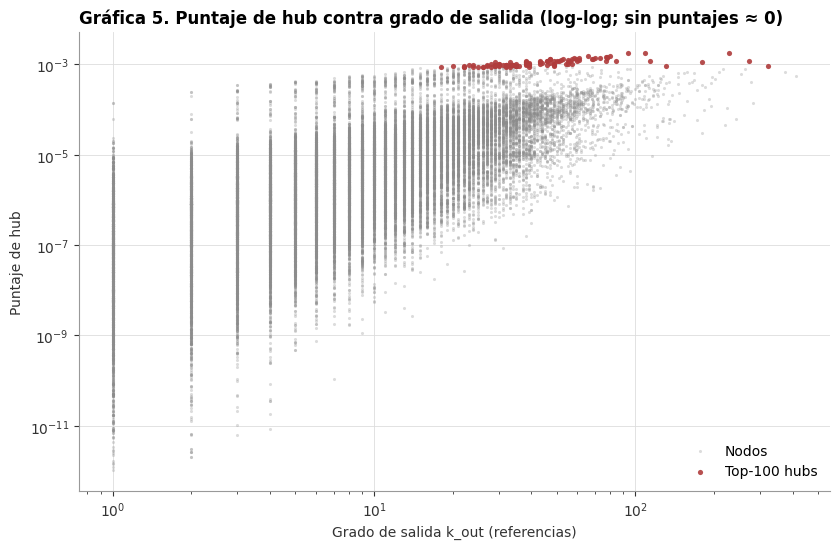

Nodos con hub ≈ 0 (no se grafican): 2,681, de ellos con k_out > 0: 221


In [22]:
# Gráfica 5. Puntaje de hub contra grado de salida (log-log)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_hub = hubs > CERO
ax.scatter(nodos.loc[con_hub, "k_out"], hubs[con_hub], s=5, color=GRIS, alpha=0.3, linewidths=0, label="Nodos")
ax.scatter(nodos.loc[top_h, "k_out"], hubs[top_h], s=14, color=ROJO, alpha=0.9, linewidths=0, label="Top-100 hubs")
ax.set_xscale("log")
ax.set_yscale("log")
estilo_ejes(ax, "Gráfica 5. Puntaje de hub contra grado de salida (log-log; sin puntajes ≈ 0)",
            "Grado de salida k_out (referencias)", "Puntaje de hub", rejilla="both")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"Nodos con hub ≈ 0 (no se grafican): {(~con_hub).sum():,}, de ellos con k_out > 0: "
      f"{((~con_hub) & (nodos['k_out'] > 0)).sum():,}")

**Observaciones: hubs y autoridades**

- **Las autoridades son los artículos muy citados de 1998–1999.** Las 12 primeras son de esos dos años (**10** de 1998)
  y la nº 1 es `9803315`, el más citado de todo el conjunto (**846** citas). Están arriba también por citas recibidas
  (lugares **1**, **2**, **6**, **36**, **8**…). Con todo, la coincidencia con el grado de entrada es parcial:
  Spearman $\rho$(autoridad, $k_{in}$) = **0.8320** y Jaccard del top-100 = **0.163**.
- **Los hubs son artículos de 1999 a 2002 con bibliografías largas, pero no las más largas.**
  - Entre los 12 primeros hay **8** de 1999, **2** de 2000 y **2** de 2002.
  - Tienen entre **58** y **229** referencias, y su lugar por $k_{out}$ va del **10** al **520**.
  - El $k_{out}$ mediano del top-100 es **39**, contra **9** de los nodos que citan algo, y $\rho$(hub, $k_{out}$) =
    **0.7702**.
  - Sin embargo, el Jaccard con el top-100 por $k_{out}$ es de solo **0.036**.

  Una bibliografía larga es casi necesaria, pero no suficiente: un buen hub cita a **las** autoridades (Gráfica 5).
- **Concentración.** El top-100 de autoridades acumula el **21.73 %** de la masa y el top-1,000, el **54.31 %**; en los
  hubs, **11.02 %** y **51.28 %**. **27,966** nodos tienen autoridad mayor que cero. **2,681** tienen hub ≈ 0, y
  **221** de ellos sí citan algo, pero solo a artículos sin peso de autoridad.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.3 PageRank contra HITS y efecto TKC</span></div>


PageRank y las autoridades de HITS miden "importancia por citas", pero de forma distinta:

- PageRank reparte el puntaje de cada artículo entre sus referencias y se teletransporta, así que es **global**.
- HITS refuerza a la vez hubs y autoridades sin teletransportación, así que se queda con la **estructura dominante**
  de $A^\top A$.

El **efecto TKC** (*Tightly Knit Community*; Lempel y Moran, 2000) es la consecuencia: una comunidad densa, en la que
muchos hubs citan a las mismas autoridades, se lleva casi todo el peso aunque no sea la más importante del grafo
completo. Se mide con:

- el traslape y la correlación de rangos entre PageRank y las autoridades;
- el año de los artículos de cada top-100;
- la **densidad del bloque** formado por los top-100 hubs y las top-100 autoridades, comparada con la del grafo.

,PageRank vs autoridad
Jaccard top-20,0.026
Jaccard top-100,0.053
"Jaccard top-1,000",0.124
Spearman ρ (todos),0.6660
Kendall τ (todos),0.4919
Spearman ρ (solo autoridad > 0),0.4031


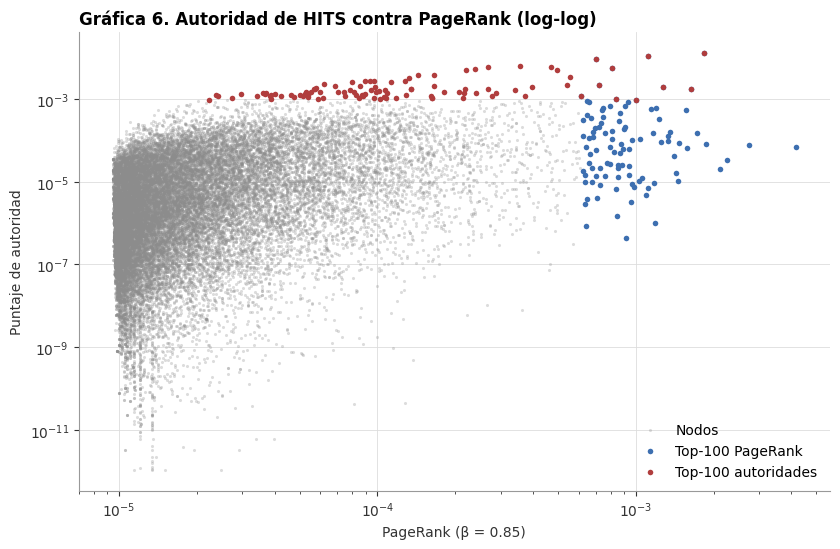

Del top-100 de PageRank, con autoridad ≈ 0: 0


In [23]:
# Comparación PageRank vs autoridades: traslape, correlación de rangos y Gráfica 6
comparacion_pr_hits = pd.Series({
    "Jaccard top-20": f"{jaccard_top(pr85, autoridades, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(pr85, autoridades, 100):.3f}",
    "Jaccard top-1,000": f"{jaccard_top(pr85, autoridades, 1000):.3f}",
    "Spearman ρ (todos)": f"{spearmanr(pr85, autoridades).statistic:.4f}",
    "Kendall τ (todos)": f"{kendalltau(pr85, autoridades).statistic:.4f}",
    "Spearman ρ (solo autoridad > 0)": f"{spearmanr(pr85[autoridades > CERO], autoridades[autoridades > CERO]).statistic:.4f}",
}, name="PageRank vs autoridad").to_frame()
display(comparacion_pr_hits)

fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_aut = autoridades > CERO
ax.scatter(pr85[con_aut], autoridades[con_aut], s=5, color=GRIS, alpha=0.3, linewidths=0, label="Nodos")
ax.scatter(pr85[pr85.nlargest(100).index], autoridades[pr85.nlargest(100).index].clip(lower=CERO), s=16, color=AZUL,
           linewidths=0, label="Top-100 PageRank")
ax.scatter(pr85[top_a], autoridades[top_a], s=16, color=ROJO, linewidths=0, label="Top-100 autoridades")
ax.set_xscale("log")
ax.set_yscale("log")
estilo_ejes(ax, "Gráfica 6. Autoridad de HITS contra PageRank (log-log)", "PageRank (β = 0.85)",
            "Puntaje de autoridad", rejilla="both")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"Del top-100 de PageRank, con autoridad ≈ 0: {(autoridades[pr85.nlargest(100).index] <= CERO).sum()}")

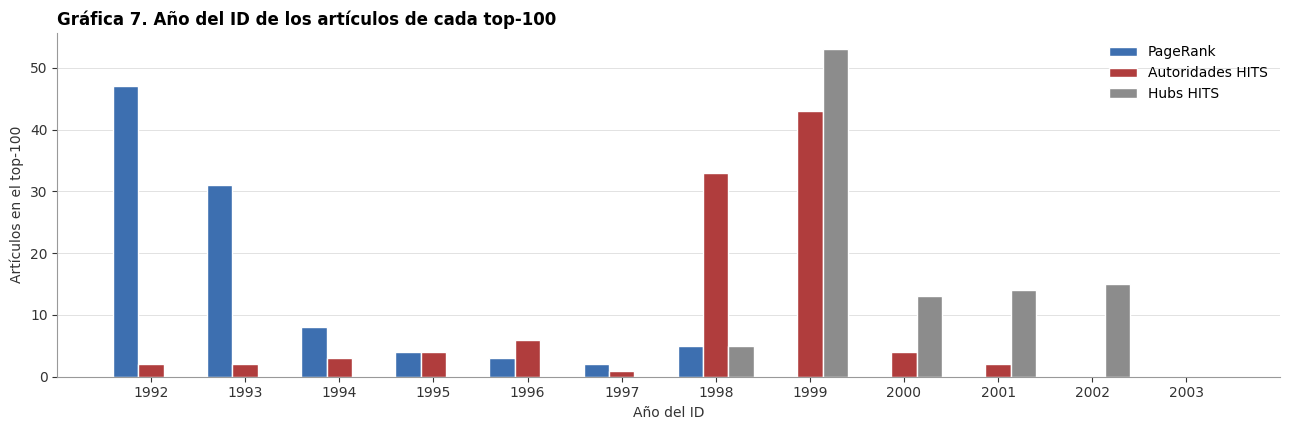

anio_id,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
PageRank,47,31,8,4,3,2,5,0,0,0,0,0
Autoridades HITS,2,2,3,4,6,1,33,43,4,2,0,0
Hubs HITS,0,0,0,0,0,0,5,53,13,14,15,0


Densidad del bloque top-100 hubs → top-100 autoridades: 0.2718 (grafo completo: 3.52e-04; 773 veces mayor)
Citas que reciben las top-100 autoridades: 15,446 | de ellas, desde los top-100 hubs: 2,718 (17.60 %)
Masa de autoridad en artículos de 1998–1999: 41.26 % | PageRank en esos años: 16.28 %


Autoridades con y sin citas al futuro: Jaccard top-100 = 0.980 | Spearman ρ = 0.9981


In [24]:
# Efecto TKC: años de cada top-100 (Gráfica 7) y densidad del bloque top-hubs → top-autoridades
top_pr = pr85.nlargest(100).index
anios_top = pd.DataFrame({"PageRank": nodos.loc[top_pr, "anio_id"].value_counts(),
                          "Autoridades HITS": nodos.loc[top_a, "anio_id"].value_counts(),
                          "Hubs HITS": nodos.loc[top_h, "anio_id"].value_counts()}).reindex(anios).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(13, 4.4))
ancho = 0.27
for desplazamiento, (col, color) in zip([-ancho, 0, ancho], [("PageRank", AZUL), ("Autoridades HITS", ROJO),
                                                             ("Hubs HITS", GRIS)]):
    ax.bar(np.array(anios) + desplazamiento, anios_top[col], width=ancho, color=color, label=col,
           edgecolor="white", linewidth=1)
ax.set_xticks(anios, labels=anios)
estilo_ejes(ax, "Gráfica 7. Año del ID de los artículos de cada top-100", "Año del ID", "Artículos en el top-100")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
display(anios_top.T)

bloque_ha = A_sf[top_h][:, top_a]
densidad_global = A_sf.nnz / n ** 2
citas_a_top_a = int(np.asarray(A_sf[:, top_a].sum(axis=0)).ravel().sum())
print(f"Densidad del bloque top-100 hubs → top-100 autoridades: {bloque_ha.nnz / 100 ** 2:.4f} "
      f"(grafo completo: {densidad_global:.2e}; {bloque_ha.nnz / 100 ** 2 / densidad_global:,.0f} veces mayor)")
print(f"Citas que reciben las top-100 autoridades: {citas_a_top_a:,} | de ellas, desde los top-100 hubs: "
      f"{bloque_ha.nnz:,} ({pct(bloque_ha.nnz / citas_a_top_a)})")
print(f"Masa de autoridad en artículos de 1998–1999: {pct(autoridades[nodos['anio_id'].isin([1998, 1999])].sum())} "
      f"| PageRank en esos años: {pct(pr85[nodos['anio_id'].isin([1998, 1999])].sum())}")

# Sensibilidad: HITS sobre el grafo completo (con citas al futuro)
_, aut_completo = nx.hits(G, max_iter=10_000, tol=1e-10)
aut_completo = pd.Series(aut_completo).sort_index()
print(f"Autoridades con y sin citas al futuro: Jaccard top-100 = {jaccard_top(aut_completo, autoridades, 100):.3f} | "
      f"Spearman ρ = {spearmanr(aut_completo, autoridades).statistic:.4f}")

**Observaciones: PageRank contra HITS y efecto TKC**

- **PageRank y HITS miden cosas distintas.** El traslape entre el top de PageRank y el de autoridades es mínimo:
  Jaccard de **0.026** (top-20), **0.053** (top-100) y **0.124** (top-1,000). La correlación de rangos es moderada:
  Spearman **0.6656** y Kendall **0.4916**, y Spearman **0.4031** si solo se cuentan los nodos con autoridad mayor que
  cero.
- **Dos nubes separadas (Gráfica 6).**
  - El top-100 de PageRank (azul) tiene PageRank alto, pero autoridades intermedias.
  - El top-100 de autoridades (rojo) tiene autoridad alta, pero un PageRank que va de valores bajos a altos.
  - Del top-100 de PageRank, **0** tiene autoridad cero: no son irrelevantes para HITS, solo no están en su comunidad.
- **Cada método elige otra época (Gráfica 7).**
  - PageRank: **47** artículos de 1992 y **31** de 1993.
  - Autoridades: **33** de 1998 y **43** de 1999.
  - Hubs: **53** de 1999, y **13**, **14** y **15** de 2000, 2001 y 2002; ninguno anterior a 1998.

  Las autoridades de 1998–1999 se llevan el **41.26 %** de la masa de autoridad, cuando en PageRank esos años solo
  tienen el **16.28 %**.
- **El efecto TKC.** El bloque de los top-100 hubs hacia las top-100 autoridades tiene una densidad de **0.2718**,
  **773 veces** la del grafo (**3.52e-04**). Esos 100 hubs aportan **2,718** de las **15,446** citas que reciben las
  top-100 autoridades (**17.60 %**). HITS encontró una **comunidad densa** de artículos de 1998–1999 y de los trabajos
  de 1999–2002 que la citan, y la pone por encima de todo lo demás. Sin metadatos de texto no se puede nombrar el tema.
  En el notebook 3 se comprobará si estos artículos caen en una misma comunidad de Louvain.
- **No es un efecto de las citas al futuro.** Con el grafo completo, las autoridades casi no cambian: Jaccard del
  top-100 = **0.980** y $\rho$ = **0.9981**.

**Decisión de uso.** **PageRank** (con el ajuste por cohorte) se usa como medida de **importancia global**. Las
**autoridades de HITS** describen la importancia **dentro de la comunidad dominante**, y los **hubs** sirven para
encontrar los artículos de revisión de 1999–2002. Que los dos métodos difieran tanto es un resultado, no un error:
muestra cuánto depende la respuesta de la definición de importancia.

> Las conclusiones y limitaciones de la práctica completa están al final de `03_topic_sensitive.ipynb`.